# 2 - Noise2Void: blind-spot self-supervision

**Noise2Void** trains a denoiser from the noisy image *alone* -- no clean targets, no second noisy copy. The trick: a network can't predict a pixel's noise from itself, so we hide ('blind-spot') the centre pixel and ask the network to predict it from its **neighbours**. Signal is spatially correlated and is recovered; noise is independent per pixel and cannot be, so it averages out.

We start from a **CelebA-HQ face** corrupted with **additive white Gaussian noise** (sigma = 25/255). Every notebook in this tutorial uses the exact same image and noise, so the PSNR numbers are directly comparable across methods.

### Setup
PyTorch ships with Colab, so there is nothing to install. We only need the data helpers.

In [1]:
!pip install -q scikit-image  # only used for the offline fallback face

### Load the CelebA face and add Gaussian noise

clean (256, 256, 3),  noise sigma = 0.098 (25/255)
noisy PSNR = 20.60 dB


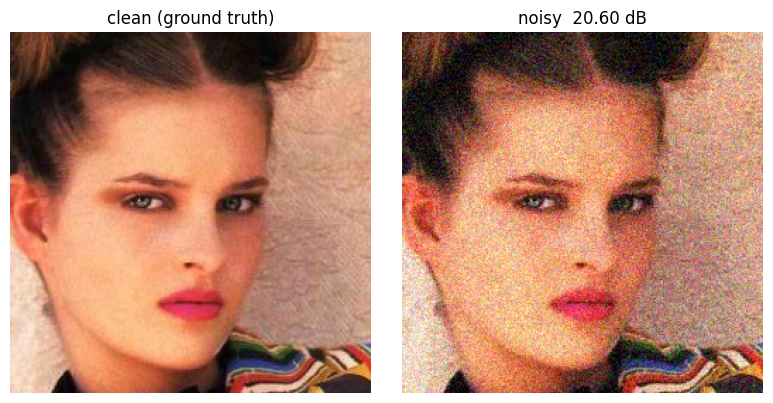

In [2]:
import io, requests, numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Reproducibility
SEED  = 0
SIGMA = 25 / 255.0          # Gaussian noise std, on the [0, 1] intensity scale
IMG   = 256                 # all notebooks use 256x256 (matches the DDPM model)

def get_celeba_face(size=IMG, index=3):
    """Fetch a single CelebA-HQ face (256x256) via the HuggingFace datasets
    server. Falls back to a bundled skimage portrait if the download fails so
    the notebook always runs offline."""
    try:
        api = ("https://datasets-server.huggingface.co/first-rows?"
               "dataset=korexyz/celeba-hq-256x256&config=default&split=train")
        rows = requests.get(api, timeout=30).json()["rows"]
        src  = rows[index]["row"]["image"]["src"]
        img  = Image.open(io.BytesIO(requests.get(src, timeout=30).content))
    except Exception as e:
        print(f"[warn] CelebA download failed ({e}); using skimage sample face.")
        from skimage.data import astronaut
        img = Image.fromarray(astronaut())
    return img.convert("RGB").resize((size, size), Image.LANCZOS)

def psnr(a, b):
    """Peak signal-to-noise ratio for images in [0, 1]."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 100.0 if mse == 0 else 20 * np.log10(1.0 / np.sqrt(mse))

# Ground truth + noisy measurement -----------------------------------------
rng   = np.random.default_rng(SEED)
clean = np.asarray(get_celeba_face(), np.float32) / 255.0            # (H,W,3) in [0,1]
noisy = np.clip(clean + rng.normal(0, SIGMA, clean.shape), 0, 1).astype(np.float32)

print(f"clean {clean.shape},  noise sigma = {SIGMA:.3f} ({SIGMA*255:.0f}/255)")
print(f"noisy PSNR = {psnr(clean, noisy):.2f} dB")

def show(images, titles, suptitle=None):
    n = len(images)
    plt.figure(figsize=(4 * n, 4))
    for k, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, n, k + 1)
        plt.imshow(np.clip(im, 0, 1)); plt.title(t); plt.axis("off")
    if suptitle: plt.suptitle(suptitle)
    plt.tight_layout(); plt.show()

show([clean, noisy], ["clean (ground truth)", f"noisy  {psnr(clean, noisy):.2f} dB"])

### A small denoising network

In [3]:
import torch, torch.nn as nn
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

class DnCNN(nn.Module):
    """A small, fast denoising CNN (~0.2M params) -- plenty for one image."""
    def __init__(self, ch=3, feat=48, depth=8):
        super().__init__()
        layers = [nn.Conv2d(ch, feat, 3, padding=1), nn.ReLU(True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(feat, feat, 3, padding=1),
                       nn.BatchNorm2d(feat), nn.ReLU(True)]
        layers += [nn.Conv2d(feat, ch, 3, padding=1)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

# noisy image as a torch tensor, shape (1, 3, H, W)
noisy_t = torch.from_numpy(noisy).permute(2, 0, 1)[None].to(device)
print("params:", sum(p.numel() for p in DnCNN().parameters()))

def aug8(img):
    """Random flip + 90-degree rotation (the 8 dihedral symmetries). Free data
    augmentation from a single image -- it stops the small network from simply
    memorising the noise."""
    if np.random.rand() < 0.5: img = torch.flip(img, [3])
    if np.random.rand() < 0.5: img = torch.flip(img, [2])
    return torch.rot90(img, int(np.random.randint(4)), [2, 3])

device: cuda
params: 127923


### Noise2Void masking
Each iteration we take a randomly flipped/rotated view of the noisy image, pick a small fraction of pixels, and **overwrite each with a random nearby neighbour** (this hides the true value from the network). The loss is computed **only at those masked pixels**, against the original noisy value. The random replacement and augmentation are what keep the tiny network from just memorising the noise.

In [4]:
def make_n2v_batch(bs=4, perc=0.02, radius=2):
    H = W = noisy.shape[0]
    inp, tgt, msk = [], [], []
    for _ in range(bs):
        img = aug8(noisy_t)                     # a fresh augmented view
        x = img.clone()
        m = torch.zeros(1, 1, H, W, device=device)
        n = int(perc * H * W)
        ii, jj = np.random.randint(0, H, n), np.random.randint(0, W, n)
        di = np.random.randint(-radius, radius+1, n)
        dj = np.random.randint(-radius, radius+1, n)
        ni, nj = np.clip(ii+di, 0, H-1), np.clip(jj+dj, 0, W-1)
        x[:, :, ii, jj] = img[:, :, ni, nj]     # blind-spot: copy a neighbour
        m[:, :, ii, jj] = 1                     # remember which pixels to score
        inp.append(x); tgt.append(img); msk.append(m)
    return torch.cat(inp), torch.cat(tgt), torch.cat(msk)

### Train
A couple of thousand iterations of this tiny network takes well under a minute on a Colab GPU.

In [5]:
import time
ITERS = 1500
net = DnCNN().to(device)
opt = torch.optim.Adam(net.parameters(), 1e-3)
net.train(); t0 = time.time()
for it in range(1, ITERS + 1):
    x, y, m = make_n2v_batch()
    out  = net(x)
    loss = ((out - y) ** 2 * m).sum() / (m.sum() * 3)   # masked MSE
    opt.zero_grad(); loss.backward(); opt.step()
    if it % 400 == 0:
        net.eval()
        with torch.no_grad():
            rec = net(noisy_t).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()
        print(f'it {it:4d}  loss {loss.item():.4f}  PSNR {psnr(clean, rec):.2f} dB')
        net.train()
print(f'trained in {time.time()-t0:.1f}s')

it  400  loss 0.0097  PSNR 29.54 dB


it  800  loss 0.0095  PSNR 30.28 dB


it 1200  loss 0.0095  PSNR 30.42 dB


trained in 26.6s


### Results
At inference we simply run the **full noisy image** through the trained network (no masking needed).

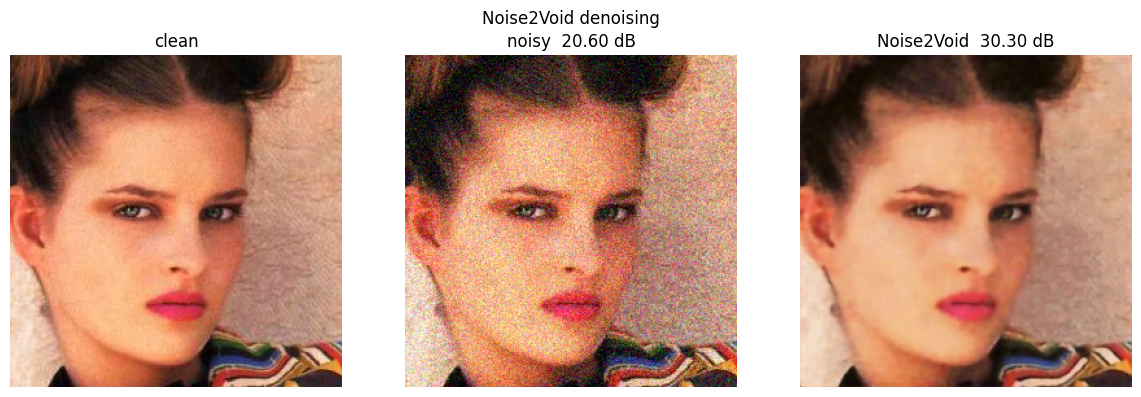

In [6]:
net.eval()
with torch.no_grad():
    den = net(noisy_t).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()
show([clean, noisy, den],
     ['clean', f'noisy  {psnr(clean, noisy):.2f} dB', f'Noise2Void  {psnr(clean, den):.2f} dB'],
     suptitle='Noise2Void denoising')

### Takeaways
* Trained on **one noisy image, no clean data, no known sigma** -- yet competitive with BM3D.
* The blind-spot prevents the network from learning the identity (copying noise through); random replacement + augmentation prevent it from memorising the noise.
* Noise2Self (next) is a cleaner, theory-grounded formulation of the same blind-spot idea.

## Try it on your own image

Upload **any** image -- colour or single-channel (e.g. a 16-bit microscopy TIFF), in **any** value range. `load_any` reads it, keeps 1 or 3 channels, and **min-max normalises it to [0, 1]**; very large images are downscaled so the longest side is at most `MAX_SIDE`.

Run the helper cell first, then the upload cell.

*Your image has no clean reference, so we simply show noisy vs. denoised (no PSNR).*

`denoise_n2v` rebuilds the network for the right number of channels and trains from scratch on your image (~1-2 min on a Colab GPU); no noise level is needed.

In [7]:
import os
from skimage.transform import resize as skresize

MAX_SIDE = 512   # large uploads are downscaled so the longest side <= MAX_SIDE

def load_any(path, max_side=MAX_SIDE):
    """Load a 1- or 3-channel image of ANY value range (8-bit, 16-bit TIFF,
    float, ...) and normalise it to float32 in [0, 1]. Returns (H, W, C)."""
    arr = np.asarray(Image.open(path)).astype(np.float32)
    if arr.ndim == 2:            # grayscale / single channel  -> (H, W, 1)
        arr = arr[..., None]
    else:                        # colour: keep up to 3 channels (drop alpha)
        arr = arr[..., :3]
    lo, hi = float(arr.min()), float(arr.max())
    arr = (arr - lo) / (hi - lo + 1e-8)                 # free range -> [0, 1]
    h, w = arr.shape[:2]
    if max_side and max(h, w) > max_side:
        s = max_side / max(h, w)
        arr = skresize(arr, (int(h*s), int(w*s), arr.shape[2]),
                       anti_aliasing=True).astype(np.float32)
    return arr.astype(np.float32)

def show_any(images, titles, suptitle=None):
    n = len(images); plt.figure(figsize=(5*n, 5))
    for k, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, n, k + 1)
        if im.shape[-1] == 1: plt.imshow(np.clip(im[..., 0], 0, 1), cmap="gray")
        else:                 plt.imshow(np.clip(im, 0, 1))
        plt.title(t); plt.axis("off")
    if suptitle: plt.suptitle(suptitle)
    plt.tight_layout(); plt.show()

def denoise_n2v(noisy, iters=1500, bs=4, perc=0.02, radius=2):
    """Run the Noise2Void recipe on one noisy image (1 or 3 channels)."""
    C  = noisy.shape[-1]
    nt = torch.from_numpy(noisy).permute(2, 0, 1)[None].to(device)
    net = DnCNN(ch=C).to(device)
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    net.train()
    for it in range(1, iters + 1):
        opt.zero_grad(); loss = 0.0
        for _ in range(bs):
            img = aug8(nt)
            h, w = img.shape[-2], img.shape[-1]
            x = img.clone(); m = torch.zeros(1, 1, h, w, device=device)
            n = max(1, int(perc * h * w))
            ii, jj = np.random.randint(0, h, n), np.random.randint(0, w, n)
            di = np.random.randint(-radius, radius+1, n)
            dj = np.random.randint(-radius, radius+1, n)
            ni, nj = np.clip(ii+di, 0, h-1), np.clip(jj+dj, 0, w-1)
            x[:, :, ii, jj] = img[:, :, ni, nj]; m[:, :, ii, jj] = 1
            out = net(x); loss = loss + ((out - img)**2 * m).sum() / (m.sum() * C)
        (loss / bs).backward(); opt.step()
        if it % 500 == 0: print(f"  it {it}/{iters}")
    net.eval()
    with torch.no_grad():
        return net(nt).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()

In [8]:
import os
IMG_PATH = None
try:
    from google.colab import files            # Colab: opens an upload dialog
    IMG_PATH = list(files.upload().keys())[0]
except Exception:
    cand = 'your_image.tif'                    # not on Colab? set a local path here
    IMG_PATH = cand if os.path.exists(cand) else None

if IMG_PATH:
    img = load_any(IMG_PATH)
    print(f'loaded {IMG_PATH}: {img.shape}, normalised to [0, 1] -- training...')
    den = denoise_n2v(img)
    show_any([img, den], ['your image (noisy)', 'Noise2Void denoised'])
else:
    print('No image yet -> on Colab use the picker above, or set '
          'IMG_PATH to a local file and re-run this cell.')

No image yet -> on Colab use the picker above, or set IMG_PATH to a local file and re-run this cell.
